# Play-style embeddings from the Match Charting Project

Each player gets a **5-dimensional embedding of how they play**, built from
the shot-by-shot Match Charting Project data, and players are compared by
**cosine similarity** between their embeddings.

1. Parse every charted point to see who hit each shot and how the point
   ended.
2. Work out **style features** per player: serve, return, rally length, shot
   mix, net play, winners and errors. Features that mostly measure how
   *good* a player is (e.g. share of serve points won) are left out, so the
   embedding is about *how* they play.
3. Adjust for **surface**: each feature is compared with the average on the
   surface the match was played on, so a player isn't marked as a grinder
   just because most of their charted matches were on clay.
4. Standardise the features and reduce them to 5 dimensions with **PCA**.
5. Compare players with cosine similarity.

Scope: men's matches from 2020 onwards (current styles), players with at
least 20 charted matches in that time.

*Data: Crowdsourced shot-by-shot professional tennis data by
[The Tennis Abstract Match Charting Project](http://www.tennisabstract.com/charting/meta.html),
licensed under [CC BY-NC-SA 4.0](http://creativecommons.org/licenses/by-nc-sa/4.0/).*

In [1]:
import glob
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

START = "2020-01-01"
MIN_MATCHES = 20
DIMENSIONS = 5

DATA = "data"
BASE = ("https://raw.githubusercontent.com/JeffSackmann/"
        "tennis_MatchChartingProject/master/")
FILES = ["charting-m-matches.csv", "charting-m-points-2010s.csv",
         "charting-m-points-2020s.csv"]
os.makedirs(DATA, exist_ok=True)
for name in FILES:
    path = os.path.join(DATA, name)
    if not os.path.exists(path):
        print("Downloading", name)
        urllib.request.urlretrieve(BASE + name, path)


def read(name):
    return pd.read_csv(os.path.join(DATA, name), encoding="latin-1",
                       low_memory=False)


matches = read("charting-m-matches.csv")
matches["Date"] = pd.to_datetime(matches["Date"].astype(str),
                                 format="%Y%m%d", errors="coerce")
matches = matches[(matches["Date"] >= START)
                  & matches["Surface"].isin(["Hard", "Clay", "Grass"])]
points = pd.concat([read(f) for f in FILES[1:]], ignore_index=True)
points = points[points["match_id"].isin(matches["match_id"])].merge(
    matches[["match_id", "Player 1", "Player 2", "Surface"]], on="match_id")
print(f"{len(matches):,} charted men's matches since {START[:4]}, "
      f"{len(points):,} points")

3,344 charted men's matches since 2020, 547,289 points


## 1. Parsing the points

The notation is explained in `eda.ipynb`. For each point:

- the **server** hits the serve; after that, shots alternate, starting with
  the **returner** (so shot 1 after the serve is the return);
- the last character says how the point ended: `*` winner (an **ace** if
  straight after the serve), `#` forced error (an **unreturned serve** if
  straight after it), `@` unforced error. The ending belongs to whoever hit
  the last shot;
- `+` marks an approach shot; `7`/`8`/`9` after the return mark its depth
  (shallow/middle/deep).

Points recorded without shots (`S`/`R` codes) are skipped.

In [2]:
SHOTS = set("fbrsvzopuylmhijktq")
SERVE_DIRECTIONS = {"4": "wide", "5": "body", "6": "T"}
FAULTS = set("nwdxge!")


def is_fault(text):
    text = str(text).lstrip("c")
    return (len(text) >= 2 and text[0] in "4560"
            and set(text[1:]) <= FAULTS)


def split_shots(rally):
    """The shots after the serve, one string per shot."""
    shots = []
    for ch in rally:
        if ch in SHOTS:
            shots.append(ch)
        elif shots:
            shots[-1] += ch
    return shots


def parse(first, second):
    if pd.isna(first) or str(first)[:1] in "SRPQ":
        return None
    first = str(first).lstrip("c")
    if not first:
        return None
    first_in = not is_fault(first)
    played = first if first_in else second
    if pd.isna(played) or not str(played).lstrip("c"):
        return None
    played = str(played).lstrip("c")
    point = dict(first_in=first_in,
                 first_direction=SERVE_DIRECTIONS.get(first[0]),
                 double_fault=not first_in and is_fault(played),
                 shots=[], ending=None)
    if not point["double_fault"]:
        point["shots"] = split_shots(played[1:])
        point["ending"] = played[-1] if played[-1] in "*#@" else None
    return point


parsed = []
for match_id, svr, first, second, p1, p2, surface in points[
        ["match_id", "Svr", "1st", "2nd", "Player 1", "Player 2",
         "Surface"]].itertuples(index=False):
    point = parse(first, second)
    if point is None:
        continue
    server, returner = (p1, p2) if svr == 1 else (p2, p1)
    parsed.append((match_id, server, returner, surface, point))
print(f"Parsed {len(parsed):,} of {len(points):,} points "
      f"({len(parsed) / len(points):.1%})")
print("Example:", parsed[1][1], "serving to", parsed[1][2], "->",
      parsed[1][4])

Parsed 546,349 of 547,289 points (99.8%)
Example: Michael Zheng serving to Jesper De Jong -> {'first_in': False, 'first_direction': 'T', 'double_fault': False, 'shots': ['f18', 'f1', 'f1', 'f3', 's3', 'f-1', 'l3*'], 'ending': '*'}


## 2. Style features

Counts are added up per player and surface, then turned into rates:

| Feature | What it measures |
|---|---|
| `first_serve_in` | share of first serves in |
| `aces`, `unreturned_serves`, `double_faults` | per service point |
| `serve_wide`, `serve_T` | where first serves are aimed (the rest go at the body) |
| `return_in_play` | share of returns put in play |
| `return_deep` | share of returns landing deep |
| `forehand_share` | forehands among groundstrokes |
| `slice_share` | slices among groundstrokes |
| `net_shots` | volleys, overheads and half-volleys among all shots |
| `approaches` | approach shots per point played |
| `drop_shots`, `lobs` | among all shots |
| `rally_length` | average shots per point played |
| `short_points` | share of points over within 3 shots |
| `winners`, `unforced_errors` | per point played (aces excluded) |

In [3]:
NET = set("vzophijk")
counts = {}  # (player, surface) -> counter dict


def add(player, surface, **values):
    c = counts.setdefault((player, surface), {})
    for key, value in values.items():
        c[key] = c.get(key, 0) + value


for _, server, returner, surface, p in parsed:
    shots, ending = p["shots"], p["ending"]
    length = 1 + len(shots)
    ace = ending == "*" and not shots
    unreturned = ending == "#" and not shots
    add(server, surface, serve_points=1, first_in=p["first_in"],
        double_faults=p["double_fault"], aces=ace, unreturned=unreturned,
        first_known=p["first_direction"] is not None,
        first_wide=p["first_direction"] == "wide",
        first_T=p["first_direction"] == "T")
    for player in (server, returner):
        add(player, surface, points=1, rally_shots=length,
            short=length <= 3)
    if shots:
        ret = shots[0]
        depth = [ch for ch in ret if ch in "789"]
        returned = not (len(shots) == 1 and ending in ("#", "@"))
        add(returner, surface, returns=1, returns_in=returned,
            returns_with_depth=bool(depth),
            returns_deep=bool(depth) and depth[0] == "9")
    elif not p["double_fault"]:
        add(returner, surface, returns=1)  # ace or unreturned serve
    for k, shot in enumerate(shots):
        hitter = returner if k % 2 == 0 else server
        kind = shot[0]
        add(hitter, surface, shots=1,
            forehands=kind in "fr", groundstrokes=kind in "fbrs",
            slices=kind in "rs", net=kind in NET, approaches="+" in shot,
            drops=kind in "uy", lobs=kind in "lm")
    if shots and ending in ("*", "@"):
        hitter = returner if (len(shots) - 1) % 2 == 0 else server
        add(hitter, surface, winners=ending == "*",
            unforced=ending == "@")

c = pd.DataFrame.from_dict(counts, orient="index").fillna(0)
c.index.names = ["player", "surface"]


def rates(c):
    return pd.DataFrame({
        "first_serve_in": c["first_in"] / c["serve_points"],
        "aces": c["aces"] / c["serve_points"],
        "unreturned_serves": c["unreturned"] / c["serve_points"],
        "double_faults": c["double_faults"] / c["serve_points"],
        "serve_wide": c["first_wide"] / c["first_known"],
        "serve_T": c["first_T"] / c["first_known"],
        "return_in_play": c["returns_in"] / c["returns"],
        "return_deep": c["returns_deep"] / c["returns_with_depth"],
        "forehand_share": c["forehands"] / c["groundstrokes"],
        "slice_share": c["slices"] / c["groundstrokes"],
        "net_shots": c["net"] / c["shots"],
        "approaches": c["approaches"] / c["points"],
        "drop_shots": c["drops"] / c["shots"],
        "lobs": c["lobs"] / c["shots"],
        "rally_length": c["rally_shots"] / c["points"],
        "short_points": c["short"] / c["points"],
        "winners": c["winners"] / c["points"],
        "unforced_errors": c["unforced"] / c["points"],
    })


by_surface = rates(c)
surface_average = rates(c.groupby(level="surface").sum())
print("Surface averages (all charted players):")
surface_average.T.round(3)

Surface averages (all charted players):


surface,Clay,Grass,Hard
first_serve_in,0.640,0.651,0.640
aces,0.054,0.102,0.093
unreturned_serves,0.030,0.041,0.043
double_faults,0.031,0.033,0.033
serve_wide,0.493,0.476,0.477
serve_T,0.409,0.436,0.436
return_in_play,0.750,0.637,0.680
return_deep,0.303,0.301,0.314
forehand_share,0.528,0.512,0.518
slice_share,0.100,0.174,0.134


The surface averages show why the adjustment matters: rallies are longer on
clay and there are more aces on grass. Each player's feature is their value
on a surface **minus that surface's average**, averaged over surfaces
weighted by how many points they played on each.

In [4]:
played = matches.melt(id_vars="match_id", value_vars=["Player 1", "Player 2"],
                      value_name="player")["player"].value_counts()
players = sorted(played[played >= MIN_MATCHES].index)

deviation = by_surface - surface_average.reindex(
    by_surface.index.get_level_values("surface")).to_numpy()
weights = c["points"]
features = (deviation.mul(weights, axis=0).groupby(level="player").sum()
            .div(weights.groupby(level="player").sum(), axis=0))
features = features.loc[players]
print(f"{len(players)} players with {MIN_MATCHES}+ charted matches since "
      f"{START[:4]}; {features.isna().sum().sum()} missing values")
features.describe().T[["mean", "std", "min", "max"]].round(3)

84 players with 20+ charted matches since 2020; 0 missing values


,mean,std,min,max
first_serve_in,0.000,0.037,-0.077,0.148
aces,-0.001,0.040,-0.062,0.143
unreturned_serves,0.008,0.028,-0.035,0.099
double_faults,-0.000,0.011,-0.019,0.038
serve_wide,0.003,0.041,-0.113,0.112
serve_T,-0.002,0.039,-0.079,0.121
return_in_play,-0.006,0.039,-0.129,0.082
return_deep,0.005,0.032,-0.086,0.093
forehand_share,0.000,0.025,-0.069,0.047
slice_share,0.008,0.058,-0.080,0.284


## 3. A 5-dimensional embedding with PCA

The features are on very different scales (aces per point vs rally length),
so each is **standardised** (mean 0, standard deviation 1 across the
players). PCA then finds the 5 directions that capture as much of the
variation between players as possible; each player's embedding is their
position along those 5 directions.

In [5]:
standardised = (features - features.mean()) / features.std()
_, singular, components = np.linalg.svd(standardised.to_numpy(),
                                        full_matrices=False)
explained = singular ** 2 / np.sum(singular ** 2)
embedding = pd.DataFrame(standardised.to_numpy() @ components[:DIMENSIONS].T,
                         index=players,
                         columns=[f"dim_{k + 1}" for k in range(DIMENSIONS)])
loadings = pd.DataFrame(components[:DIMENSIONS].T, index=features.columns,
                        columns=embedding.columns)
print("Share of the variation captured by each dimension:",
      ", ".join(f"{e:.0%}" for e in explained[:DIMENSIONS]),
      f"(total {explained[:DIMENSIONS].sum():.0%})")

Share of the variation captured by each dimension: 26%, 12%, 10%, 9%, 8% (total 64%)


What each dimension means: the features that load most strongly on it
(positive and negative). The sign of a dimension is arbitrary; what matters
is which features go together.

In [6]:
for dim in loadings.columns:
    top = loadings[dim].sort_values()
    neg = ", ".join(f"{f} ({v:+.2f})" for f, v in top.head(3).items())
    pos = ", ".join(f"{f} ({v:+.2f})" for f, v in top.tail(3)[::-1].items())
    high = embedding[dim].nlargest(4).index
    low = embedding[dim].nsmallest(4).index
    print(f"{dim}: + {pos}\n       - {neg}")
    print(f"       highest: {', '.join(high)}")
    print(f"       lowest:  {', '.join(low)}\n")

dim_1: + short_points (+0.45), aces (+0.36), unreturned_serves (+0.31)
       - rally_length (-0.44), return_in_play (-0.37), lobs (-0.19)
       highest: Maxime Cressy, Reilly Opelka, Giovanni Mpetshi Perricard, John Isner
       lowest:  Jenson Brooksby, Diego Schwartzman, Alex De Minaur, Jaume Munar

dim_2: + slice_share (+0.43), lobs (+0.40), drop_shots (+0.37)
       - unforced_errors (-0.34), return_deep (-0.21), unreturned_serves (-0.13)
       highest: Alexander Bublik, Maxime Cressy, Daniel Evans, Pedro Martinez
       lowest:  Ugo Humbert, Adrian Mannarino, Nicolas Jarry, Emil Ruusuvuori

dim_3: + winners (+0.48), unforced_errors (+0.39), drop_shots (+0.36)
       - serve_wide (-0.37), first_serve_in (-0.24), net_shots (-0.17)
       highest: Alexander Bublik, Denis Shapovalov, Fabian Marozsan, Aslan Karatsev
       lowest:  Maxime Cressy, John Isner, Richard Gasquet, Thanasi Kokkinakis

dim_4: + serve_wide (+0.34), approaches (+0.30), winners (+0.29)
       - serve_T (-0.66)

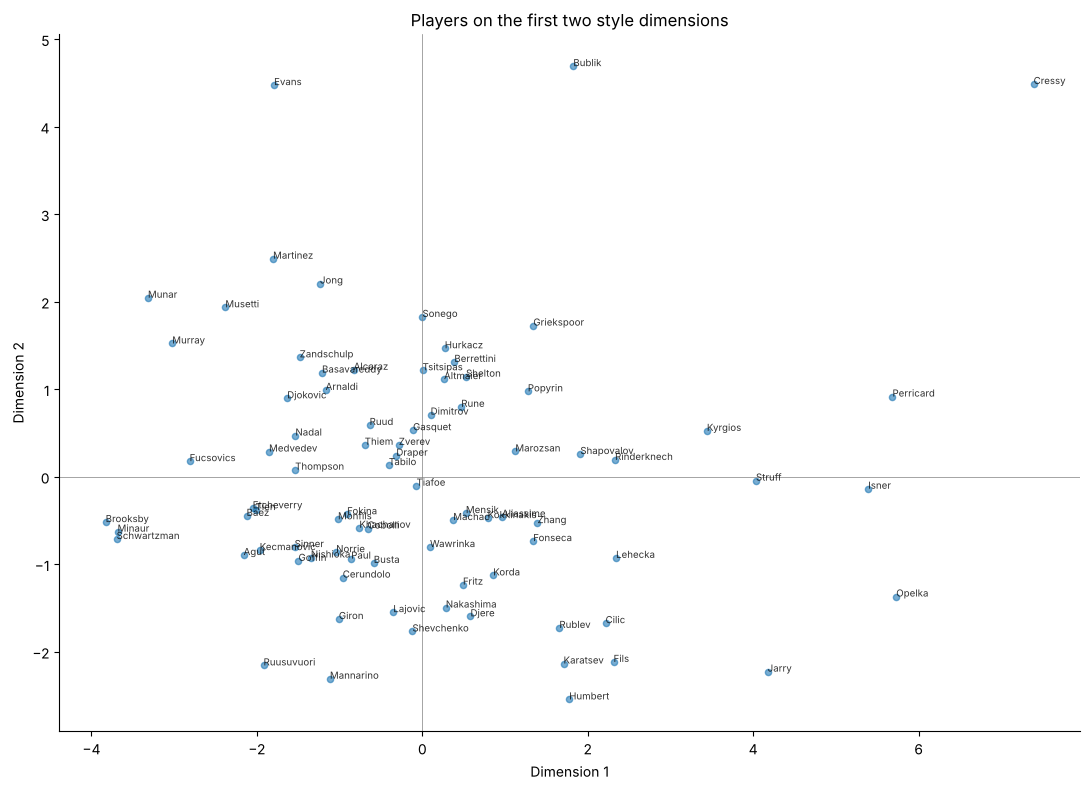

In [7]:
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(embedding["dim_1"], embedding["dim_2"], s=20, alpha=0.6)
for name, row in embedding.iterrows():
    ax.annotate(name.split()[-1], (row["dim_1"], row["dim_2"]), fontsize=7,
                alpha=0.8)
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel("Dimension 1")
ax.set_ylabel("Dimension 2")
ax.set_title("Players on the first two style dimensions")
plt.tight_layout()

## 4. Cosine similarity

Cosine similarity compares the **direction** of two embeddings: 1 means
the same mix of style traits, 0 unrelated, -1 opposite. It ignores how far
from average a player is, so a mildly serve-heavy player and an extreme one
count as similar.

In [8]:
unit = embedding.div(np.linalg.norm(embedding, axis=1), axis=0)
similarity = pd.DataFrame(unit.to_numpy() @ unit.to_numpy().T,
                          index=players, columns=players)

examples = ["Jannik Sinner", "Carlos Alcaraz", "Novak Djokovic",
            "Daniil Medvedev", "Hubert Hurkacz", "Casper Ruud",
            "Alexander Bublik", "Alex De Minaur"]
for name in [e for e in examples if e in players]:
    nearest = similarity[name].drop(name).nlargest(5)
    print(f"{name}: " + ", ".join(f"{p} ({s:.2f})"
                                  for p, s in nearest.items()))

Jannik Sinner: Jenson Brooksby (0.83), Alex De Minaur (0.75), Diego Schwartzman (0.74), Daniil Medvedev (0.74), Flavio Cobolli (0.73)
Carlos Alcaraz: Pedro Martinez (0.88), Grigor Dimitrov (0.85), Holger Rune (0.84), Alejandro Tabilo (0.78), Botic Van De Zandschulp (0.70)
Novak Djokovic: Andy Murray (0.96), Jaume Munar (0.91), Rafael Nadal (0.86), Dominic Thiem (0.81), Daniil Medvedev (0.80)
Daniil Medvedev: Flavio Cobolli (0.92), Gael Monfils (0.90), Novak Djokovic (0.80), Jack Draper (0.80), Alexander Zverev (0.76)
Hubert Hurkacz: Daniel Altmaier (0.92), Ben Shelton (0.87), Tallon Griekspoor (0.80), Lorenzo Sonego (0.76), Casper Ruud (0.69)
Casper Ruud: Daniel Altmaier (0.84), Tomas Martin Etcheverry (0.84), Lorenzo Musetti (0.73), Jordan Thompson (0.69), Hubert Hurkacz (0.69)
Alexander Bublik: Matteo Berrettini (0.90), Stefanos Tsitsipas (0.81), Alexei Popyrin (0.71), Denis Shapovalov (0.66), Jesper De Jong (0.66)
Alex De Minaur: Diego Schwartzman (0.98), Learner Tien (0.97), Jenson

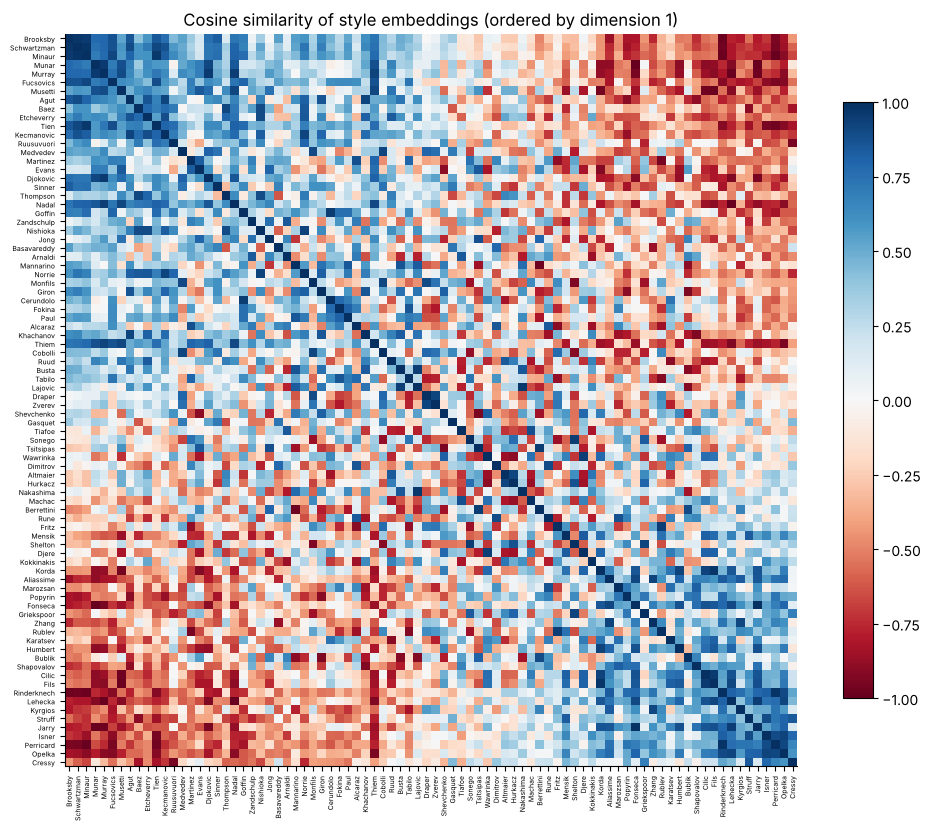

In [9]:
order = embedding.sort_values("dim_1").index
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(similarity.loc[order, order], cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)))
ax.set_yticks(range(len(order)))
ax.set_xticklabels([p.split()[-1] for p in order], rotation=90, fontsize=5)
ax.set_yticklabels([p.split()[-1] for p in order], fontsize=5)
ax.set_title("Cosine similarity of style embeddings (ordered by dimension 1)")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()

## 5. Saving the embeddings

The embeddings and the similarity matrix are saved to `data/` for other
notebooks (e.g. to check whether similar players over-perform against the
same opponents).

In [10]:
embedding.to_csv(os.path.join(DATA, "style_embeddings.csv"))
similarity.to_csv(os.path.join(DATA, "style_similarity.csv"))
features.to_csv(os.path.join(DATA, "style_features.csv"))
print("Saved style_embeddings.csv, style_similarity.csv and "
      "style_features.csv to data/")

Saved style_embeddings.csv, style_similarity.csv and style_features.csv to data/


## Summary

- **84 players** with 20+ charted matches since 2020, described by 18
  surface-adjusted style features, reduced to 5 dimensions that capture 64%
  of the variation between players.
- **The dimensions are readable**:
  1. **Serve-first vs baseline** (26%): aces, unreturned serves and short
     points against long rallies and returns in play. Cressy, Opelka,
     Mpetshi Perricard and Isner at one end; Brooksby, Schwartzman, De Minaur
     and Munar at the other.
  2. **Variety** (12%): slices, lobs and drop shots against unforced errors.
     Bublik, Cressy, Evans and Martinez at the top; flat hitters such as
     Humbert, Mannarino and Jarry at the bottom.
  3. **Risk** (10%): winners and unforced errors together (Bublik,
     Shapovalov, Marozsan, Karatsev).
  4. and 5. Smaller dimensions about **serve direction** (wide vs down the
     T) and **forehand vs backhand use** (Medvedev, Gasquet and Monfils hit
     relatively more backhands).
- **The similarities mostly make sense**: De Minaur is closest to
  Schwartzman, Tien and Brooksby (fast counter-punchers); Djokovic to Murray,
  Munar and Nadal; Medvedev to Cobolli and Monfils.
- **Limits**: the features describe what players do, not how hard or well
  they do it, so two players with the same shot mix but very different pace
  or quality (e.g. Sinner and Brooksby) can look alike. Charting only covers
  some of each player's matches, and opponents shape a player's stats too
  (everyone plays longer rallies against De Minaur).

Next steps: use the saved embeddings to check whether players with similar
styles over-perform against the same opponents (the Elo residuals from `nmf.ipynb`),
or add more features, e.g. shot direction (crosscourt vs down
the line) or serve-plus-one patterns.